# Anscombe's Quartet: Why Visualization Matters
### Core Lesson: Numerical summaries alone can conceal critical patterns, non-linearities, and severe outliers.

In 1973, English statistician **Francis Anscombe** constructed four synthetic datasets to demonstrate two fundamental truths:
1. Numerical calculations and summary statistics alone are not enough to understand data.
2. Looking at data graphically is essential before applying statistical models.

Each dataset contains $N = 11$ points $(x, y)$. All four share **nearly identical descriptive statistics** (mean, variance, correlation, and regression line), yet their underlying geometric distributions are radically different.

---
*Reference: Anscombe, F. J. (1973). "Graphs in Statistical Analysis". The American Statistician, 27(1), 17–21. Adapted from the [Matplotlib Gallery](https://matplotlib.org/stable/gallery/specialty_plots/anscombe.html).*

## 1. The Four Datasets and Their Summary Statistics
Let us define the four datasets and compute their standard summary statistics:
- Means of $x$ and $y$ ($\bar{x}, \bar{y}$)
- Sample standard deviations of $x$ and $y$ ($s_x, s_y$)
- Pearson correlation coefficient ($r$) and coefficient of determination ($R^2$)
- Linear regression fit: $y = \text{intercept} + \text{slope} \cdot x$

In [1]:
# Load analytical libraries
import numpy as np
import pandas as pd

# Define the four (x, y) datasets of Anscombe's Quartet (N = 11 pairs each)
x = np.array([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5])
y1 = np.array([8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68])
y2 = np.array([9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74])
y3 = np.array([7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73])
x4 = np.array([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8])
y4 = np.array([6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89])

# Organize datasets with descriptive labels
datasets = {
    'I': (x, y1, 'Linear relationship'),
    'II': (x, y2, 'Non-linear (quadratic)'),
    'III': (x, y3, 'Linear with outlier in y'),
    'IV': (x4, y4, 'Influential leverage point in x')
}

# Compute and compare summary statistics side-by-side
summary_rows = []
for label, (xv, yv, _) in datasets.items():
    slope, intercept = np.polyfit(xv, yv, deg=1)  # Ordinary Least Squares (OLS) fit
    r = np.corrcoef(xv, yv)[0, 1]                 # Pearson correlation coefficient
    summary_rows.append({
        'Dataset': f'Dataset {label}',
        'Mean(x)': f'{np.mean(xv):.2f}',
        'Std(x)': f'{np.std(xv, ddof=1):.2f}',
        'Mean(y)': f'{np.mean(yv):.2f}',
        'Std(y)': f'{np.std(yv, ddof=1):.2f}',
        'Corr (r)': f'{r:.3f}',
        'R²': f'{r**2:.2f}',
        'Regression Line': f'y = {intercept:.2f} + {slope:.2f}x'
    })

stats_df = pd.DataFrame(summary_rows)
stats_df


Dataset,Mean(x),Std(x),Mean(y),Std(y),Corr (r),R²,Regression Line
Dataset I,9.00,3.32,7.50,2.03,0.816,0.67,y = 3.00 + 0.50x
Dataset II,9.00,3.32,7.50,2.03,0.816,0.67,y = 3.00 + 0.50x
Dataset III,9.00,3.32,7.50,2.03,0.816,0.67,y = 3.00 + 0.50x
Dataset IV,9.00,3.32,7.50,2.03,0.817,0.67,y = 3.00 + 0.50x


## 2. Visualizing the Four Datasets
Looking only at the summary table above, one might assume all four datasets describe identical relationships.

Now let us plot them on a synchronized 2×2 grid with their shared linear regression line ($y = 3.00 + 0.50x$) overlaid in red dashed style.

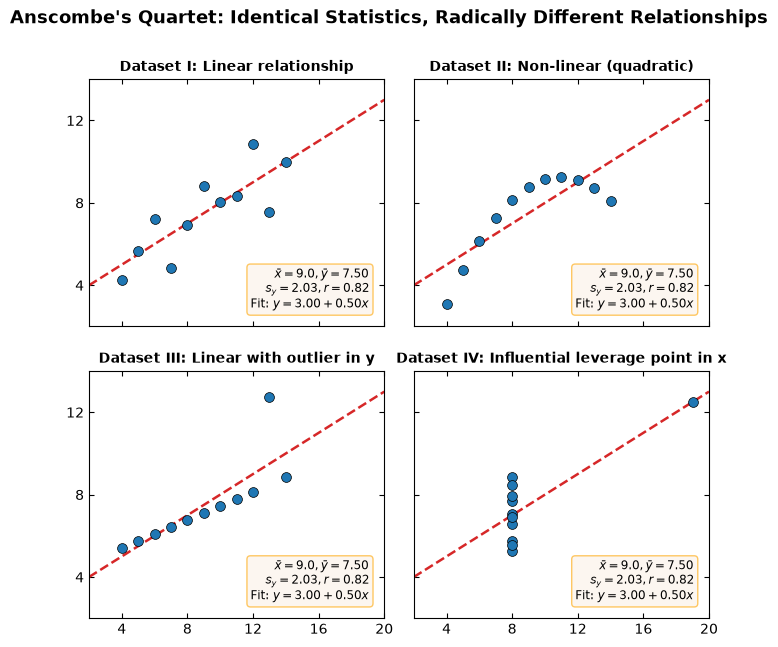

In [2]:
# Import visualization library
import matplotlib.pyplot as plt

# Create 2x2 subplot grid with shared axes for honest direct comparison
fig, axs = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(8, 7),
                        gridspec_kw={'wspace': 0.10, 'hspace': 0.18})
fig.suptitle("Anscombe's Quartet: Identical Statistics, Radically Different Relationships",
             fontsize=13, fontweight='bold', y=0.98)

# Styling for the summary statistics callout box
bbox_props = dict(boxstyle='round,pad=0.3', fc='linen', ec='orange', alpha=0.6)

# Plot each dataset on its corresponding subplot
for ax, (label, (xv, yv, title)) in zip(axs.flat, datasets.items()):
    # Inward ticks and uniform axis limits across all four plots
    ax.tick_params(direction='in', top=True, right=True)
    ax.set(xlim=(2, 20), ylim=(2, 14), xticks=(4, 8, 12, 16, 20), yticks=(4, 8, 12))
    
    # 1. Scatter plot of observations
    ax.scatter(xv, yv, color='#1f77b4', s=50, edgecolors='black', linewidth=0.5, zorder=3)
    
    # 2. Linear regression line (y = 3.00 + 0.50x)
    slope, intercept = np.polyfit(xv, yv, deg=1)
    ax.axline(xy1=(0, intercept), slope=slope, color='#d62728', lw=1.8, linestyle='--', zorder=2)
    
    # 3. Subplot title indicating dataset label and structure
    ax.set_title(f'Dataset {label}: {title}', fontsize=10, fontweight='bold', pad=6)
    
    # 4. Inset text box showing the key statistical values
    r = np.corrcoef(xv, yv)[0, 1]
    stats_text = (f'$\bar{{x}} = {np.mean(xv):.1f}, \bar{{y}} = {np.mean(yv):.2f}$\n'
                  f'$s_y = {np.std(yv, ddof=1):.2f}, r = {r:.2f}$\n'
                  f'Fit: $y = {intercept:.2f} + {slope:.2f}x$')
    ax.text(0.95, 0.06, stats_text, fontsize=8.5, bbox=bbox_props,
            transform=ax.transAxes, ha='right', va='bottom')

plt.show()


## 3. Takeaways for Data Analytics:
1. **Never trust summary statistics in isolation:** Metrics like the mean, variance, correlation can be identical for datasets with completely different structures.
2. **Always visualize before modeling:** Visual exploration immediately reveals non-linearity, outliers, clustering, and data quality issues that summary metrics hide.
3. **Inspect outliers:** A single extreme observation can completely distort statistical measures and linear regression lines.